# Chapter 8 companion notebook: inference and serving

This notebook reproduces the quantitative results in Chapter 8. It has three kinds
of cell:

- **Analytical cells** run here and now on CPU. They import the same modules the
  chapter ships (`kv_calc`, `paged_kv`, `spec_math`, `pd_size`, `tiled_attention`),
  so the tables and figures are computed live, not pasted in.
- **KV-capacity cells** work out the bytes of KV cache per token from a model's
  shape and check the result against the cache size vLLM actually reported on the
  GPU, so the arithmetic and the engine agree.
- **Measured serving cells** read the case-study results committed under
  `results/` (five GPU/model pairs served with vLLM 0.32.0 on Modal) and rebuild
  the latency, goodput, long-context, prefix-caching and speculative-decoding
  tables, plus the load-sweep figure. Serving the models needs GPUs and a Modal
  account, so those numbers are read from the committed JSON; the last cell gives
  the exact command that produced them.

Everything modeled is labeled modeled and everything measured is labeled measured.

The measured numbers here were served with the load generator as of commit 7075525,
one step before the client's default 100-connection cap was lifted (aac7321). In
these runs the requests in flight stayed well under 100, so the cap was not binding
and the results are unaffected; a rerun on the current load generator reproduces them.


In [1]:
import sys, os, json, glob, pathlib

# Import the chapter's own modules so the notebook computes rather than restates.
HERE = pathlib.Path(os.path.abspath("")).resolve()
sys.path.insert(0, str(HERE))

import paged_kv, spec_math, pd_size, tiled_attention, kv_calc
RES = HERE / "results"
print("modules loaded:", [m.__name__ for m in (kv_calc, paged_kv, spec_math, pd_size, tiled_attention)])
print("results dir:", RES, "|", len(sorted(RES.glob("*.json"))), "result files")

RAG       prefill  2.6  decode   0.8 GPUs  batch 107 (KV limit 107)
chat      prefill  0.3  decode   0.3 GPUs  batch 627 (KV limit 627)
reasoning prefill  0.6  decode  12.0 GPUs  batch 146 (KV limit 146)


modules loaded: ['kv_calc', 'paged_kv', 'spec_math', 'pd_size', 'tiled_attention']
results dir: /Users/kaoutar-elmaghraoui/Documents/hpml/High-Performance-Machine-Learning/chapter08/results | 5 result files


/Users/kaoutar-elmaghraoui/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## How much KV cache does a token cost?

Every token kept in the KV cache stores a key and a value in each layer, for each
key/value head. With grouped-query attention the number of KV heads is far smaller
than the number of query heads, which is why Gemma-2B (one KV head) is so much
cheaper per token than its parameter count suggests, and why Llama-3.1-8B (eight KV
heads) is the model that makes the cache, not the weights, the limit on batch size.

$$\text{bytes/token} = 2 \times L \times n_{\text{kv}} \times d_{\text{head}} \times \text{bytes}_{\text{dtype}}$$

The factor of two is the key and the value. The cell below uses `kv_calc`'s own
formula on the two case-study models. Their configs are gated on Hugging Face, so
the shapes are given here as the public, in-book values; the function is the same
one `kv_calc.py` runs on a live config.


In [2]:
# (num_hidden_layers, num_key_value_heads, head_dim) for the two case-study generators, FP16/BF16 KV (2 bytes).
MODELS = {
    "google/gemma-2b-it":              dict(L=18, kv_heads=1, head_dim=256, dtype_bytes=2),
    "meta-llama/Llama-3.1-8B-Instruct": dict(L=32, kv_heads=8, head_dim=128, dtype_bytes=2),
}

def kv_bytes_per_token(L, kv_heads, head_dim, dtype_bytes):
    return 2 * L * kv_heads * head_dim * dtype_bytes     # the formula kv_calc.kv_bytes_per_token uses

print(f"{'model':<34}{'KV bytes/token':>16}{'per 4K seq':>14}")
print("-" * 64)
for name, c in MODELS.items():
    b = kv_bytes_per_token(**c)
    print(f"{name:<34}{b:>13,} B{b*4096/2**30:>11.2f} GiB")

model                               KV bytes/token    per 4K seq
----------------------------------------------------------------
google/gemma-2b-it                       18,432 B       0.07 GiB
meta-llama/Llama-3.1-8B-Instruct        131,072 B       0.50 GiB


### The arithmetic agrees with the engine

The capacity a server has for tokens is the memory left after weights and overhead,
divided by the per-token cost above. The cell below works out that capacity from the
KV memory vLLM reported at startup, and compares it with the cache size the engine
printed. They match to rounding, which is the point: the paged cache is exactly this
arithmetic, with no hidden cost per token.


In [3]:
# KV memory vLLM reported (GiB) and the cache size it printed (tokens), from each run's startup log.
MEASURED = {
    "google/gemma-2b-it":              dict(kv_gib=66.52, reported_tokens=3_874_864, gpu="A100-80GB"),
    "meta-llama/Llama-3.1-8B-Instruct": dict(kv_gib=55.06, reported_tokens=451_040,  gpu="H100"),
}
print(f"{'model':<34}{'GPU':>10}{'computed tok':>15}{'engine tok':>13}{'rel. err':>10}")
print("-" * 82)
for name, m in MEASURED.items():
    b = kv_bytes_per_token(**MODELS[name])
    computed = int(m["kv_gib"] * 2**30 // b)
    err = abs(computed - m["reported_tokens"]) / m["reported_tokens"]
    print(f"{name:<34}{m['gpu']:>10}{computed:>15,}{m['reported_tokens']:>13,}{err:>9.2%}")

model                                    GPU   computed tok   engine tok  rel. err
----------------------------------------------------------------------------------
google/gemma-2b-it                 A100-80GB      3,875,070    3,874,864    0.01%
meta-llama/Llama-3.1-8B-Instruct        H100        451,051      451,040    0.00%


## The paged KV cache: block tables, sharing and copy-on-write

`paged_kv.py` is a tensor-free model of vLLM's block manager. It allocates
fixed-size blocks, keeps a block table per request, reference-counts blocks so
several requests can share a prefix, and copies a shared block before writing it
(copy-on-write). The cell below reproduces the chapter's walkthrough: two requests
that share a 48-token system prompt, then a forked second sample that shares every
block until it writes.


In [4]:
kv = paged_kv.PagedKVCache(num_blocks=64, block_size=16)
system = list(range(1000, 1048))                        # 48-token system prompt: three full blocks

hits_A = kv.add_request("A", system + [1, 2, 3, 4, 5])  # A: no cache yet, fills the three prompt blocks
hits_B = kv.add_request("B", system + [9, 9, 9])        # B: same system prompt, reuses A's three full blocks
print(f"request A prefix-block hits: {hits_A}")
print(f"request B prefix-block hits: {hits_B}   <- B skips prefill on the shared system prompt")

for _ in range(20):                                     # A decodes 20 tokens, growing its block table
    kv.append_token("A")
kv.fork("B", "B2")                                      # a second sample of B shares all of B's blocks
kv.append_token("B2")                                   # first write triggers copy-on-write of the last block

print("block tables:", {r: t for r, t in kv.tables.items()})
print("physical blocks in use:", kv.used_blocks(), "of 64")

request A prefix-block hits: 0
request B prefix-block hits: 3   <- B skips prefill on the shared system prompt
block tables: {'A': [0, 1, 2, 3, 5], 'B': [0, 1, 2, 4], 'B2': [0, 1, 2, 6]}
physical blocks in use: 7 of 64


The prefix hits on request B are the whole case for automatic prefix caching: the
shared system prompt is prefilled once and reused, so B's time to first token drops.
The measured version of exactly this effect is in the prefix-caching cell below.


## Attention tile by tile: the online softmax

FlashAttention never builds the full attention matrix. It streams over key/value
tiles, keeping a running max and running denominator so the softmax stays exact
without being materialized. Flash-Decoding splits the keys across units and combines
the partial results with their log-sum-exp. `tiled_attention.py` implements both and
checks them against the textbook `softmax(QK^T)V`; the cell runs that check in double
precision.


In [5]:
import torch
torch.manual_seed(0)
q, k, v = (torch.randn(1024, 64, dtype=torch.float64) for _ in range(3))
ref = torch.softmax(q @ k.T / 8, dim=-1) @ v            # the reference we must match

err_tiled = (tiled_attention.tiled_attention(q, k, v) - ref).abs().max().item()
err_split = (tiled_attention.split_kv_attention(q[:1], k, v) - ref[:1]).abs().max().item()
print(f"online-softmax tiling   max abs error vs reference: {err_tiled:.2e}")
print(f"split-KV (Flash-Decode) max abs error vs reference: {err_split:.2e}")
print("both ~1e-15: tiling and the split-KV combine are exact, not approximations")

online-softmax tiling   max abs error vs reference: 6.11e-16
split-KV (Flash-Decode) max abs error vs reference: 2.22e-16
both ~1e-15: tiling and the split-KV combine are exact, not approximations


## Speculative decoding: expected tokens and modeled speedup

A draft proposes `gamma` tokens; the target verifies them in one pass and accepts a
prefix. With acceptance probability `alpha` per token, the expected number of tokens
produced per target pass and the modeled speedup follow Leviathan et al. (2023).
`spec_math.py` is those two formulas. The cell sweeps the draft length and marks the
best choice for each acceptance rate, which is the shape of the chapter's figure.


alpha=0.6: E[tokens|gamma=4]=2.31, speedup(gamma=4)=1.92x, best gamma=4 (1.92x)
alpha=0.8: E[tokens|gamma=4]=3.36, speedup(gamma=4)=2.80x, best gamma=8 (3.09x)
alpha=0.9: E[tokens|gamma=4]=4.10, speedup(gamma=4)=3.41x, best gamma=13 (4.67x)


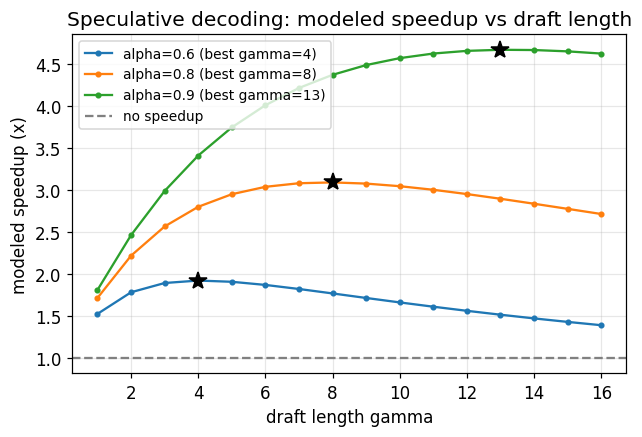

In [6]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.3})

c = 0.05                                                 # draft step cost relative to a target step
gammas = np.arange(1, 17)
fig, ax = plt.subplots(figsize=(6.5, 4))
for alpha in (0.6, 0.8, 0.9):
    sp = [spec_math.speedup(alpha, int(g), c) for g in gammas]
    best = int(max(gammas, key=lambda g: spec_math.speedup(alpha, int(g), c)))
    ax.plot(gammas, sp, marker="o", ms=3, label=f"alpha={alpha} (best gamma={best})")
    ax.plot(best, spec_math.speedup(alpha, best, c), "k*", ms=12)
    print(f"alpha={alpha}: E[tokens|gamma=4]={spec_math.expected_tokens(alpha,4):.2f}, "
          f"speedup(gamma=4)={spec_math.speedup(alpha,4,c):.2f}x, best gamma={best} "
          f"({spec_math.speedup(alpha,best,c):.2f}x)")
ax.axhline(1.0, ls="--", color="gray", label="no speedup")
ax.set_xlabel("draft length gamma"); ax.set_ylabel("modeled speedup (x)")
ax.set_title("Speculative decoding: modeled speedup vs draft length"); ax.legend(fontsize=9)
plt.show()

The modeled speedup says what is possible at a given acceptance rate. The measured
speculative-decoding cell below shows what n-gram (prompt-lookup) drafting actually
achieved on each GPU, and why its benefit shrinks as the batch fills.


## Sizing prefill and decode pools (disaggregated serving)

Prefill is compute-bound; decode is memory-bandwidth-bound. Serving them in separate
pools lets each scale on its own bottleneck. `pd_size.py` is a Roofline estimate: for
a given request rate and shape, how many prefill GPUs and how many decode GPUs, and
what decode batch the KV capacity allows. The cell runs it for three workloads on an
H100 serving Llama-3.1-8B.


In [7]:
h100 = {"peak": 989e12, "bw": 3.35e12, "mem": 80e9}
llama8b = {"w": 16.06e9, "kv": 131072, "flop_tok": 2 * 8.03e9}
workloads = [("RAG", 4000, 200), ("chat", 500, 400), ("reasoning", 1000, 4000)]

print(f"{'workload':<11}{'prefill GPUs':>13}{'decode GPUs':>13}{'decode batch':>14}{'KV limit':>10}")
print("-" * 61)
for name, prompt, out in workloads:
    p, d, b, fit = pd_size.size_pools(20, prompt, out, 0.05, h100, llama8b)
    print(f"{name:<11}{p:>13.1f}{d:>13.1f}{b:>14d}{fit:>10d}")
print("\n(modeled: rate 20 req/s, TPOT target 50 ms, prefill efficiency 0.5)")

workload    prefill GPUs  decode GPUs  decode batch  KV limit
-------------------------------------------------------------
RAG                  2.6          0.8           107       107
chat                 0.3          0.3           627       627
reasoning            0.6         12.0           146       146

(modeled: rate 20 req/s, TPOT target 50 ms, prefill efficiency 0.5)


## Measured serving results

The cells from here read the committed `results/<gpu>_<model>.json` files. Each file
is one GPU/model pair served with a fresh `vllm serve` on Modal (vLLM 0.32.0),
measured by the open-loop Poisson load generator `loadgen.py`. The SLOs are TTFT
500 ms and TPOT 50 ms (2 s TTFT for the 4K long-context study); outputs are 128
tokens (1,024 for the long study).


In [8]:
data = {p.stem: json.loads(p.read_text()) for p in sorted(RES.glob("*.json"))}
print(f"{'file':<22}{'GPU':<26}{'model':<34}{'vLLM':>7}")
print("-" * 89)
for stem, d in data.items():
    e = d.get("env", {})
    print(f"{stem:<22}{e.get('gpu','?'):<26}{e.get('model','?'):<34}{e.get('vllm','?'):>7}")

file                  GPU                       model                                vLLM
-----------------------------------------------------------------------------------------
A100-80GB_gemma       NVIDIA A100-SXM4-80GB, 81920 MiB, 610.57.04google/gemma-2b-it                 0.32.0
A100-80GB_llama       NVIDIA A100-SXM4-80GB, 81920 MiB, 610.57.04meta-llama/Llama-3.1-8B-Instruct   0.32.0
H100_gemma            NVIDIA H100 80GB HBM3, 81559 MiB, 610.57.04google/gemma-2b-it                 0.32.0
H100_llama            NVIDIA H100 80GB HBM3, 81559 MiB, 610.57.04meta-llama/Llama-3.1-8B-Instruct   0.32.0
T4_gemma              Tesla T4, 15360 MiB, 610.57.04google/gemma-2b-it                 0.32.0


### Single-request latency: the floor

At 0.25 req/s there is no queueing, so this is the latency floor each GPU imposes.
TPOT p50 should sit at the per-token weight-read time and match ITL p50; `text chunks
per token` near 1.0 confirms the client timed one streamed token per chunk.


In [9]:
print(f"{'file':<22}{'TTFT p50':>10}{'TPOT p50':>10}{'ITL p50':>9}{'chunks/tok':>12}")
print("-" * 63)
for stem, d in data.items():
    s = d.get("single", {}).get("result", {})
    if "ttft_ms" not in s:
        print(f"{stem:<22}  (no single result)"); continue
    print(f"{stem:<22}{s['ttft_ms']['p50']:>8.0f}ms{s['tpot_ms']['p50']:>8.2f}ms"
          f"{s['itl_ms']['p50']:>7.2f}ms{s.get('text_chunks_per_token',0):>12.2f}")

file                    TTFT p50  TPOT p50  ITL p50  chunks/tok
---------------------------------------------------------------
A100-80GB_gemma             29ms    4.27ms   4.23ms        1.00
A100-80GB_llama             58ms   10.84ms  10.82ms        1.00
H100_gemma                  19ms    2.37ms   2.38ms        1.00
H100_llama                  22ms    6.45ms   6.44ms        1.00
T4_gemma                   181ms   22.13ms  21.52ms        1.00


### Load sweep: throughput, tail latency and goodput

Offered load rises as a Poisson process. Throughput climbs until the server
saturates; TTFT p99 is flat while there is headroom and then runs away as the queue
builds; goodput (requests per second meeting both SLOs) is the number that matters
for capacity planning. This rebuilds `results/sweep.png` from the same data.


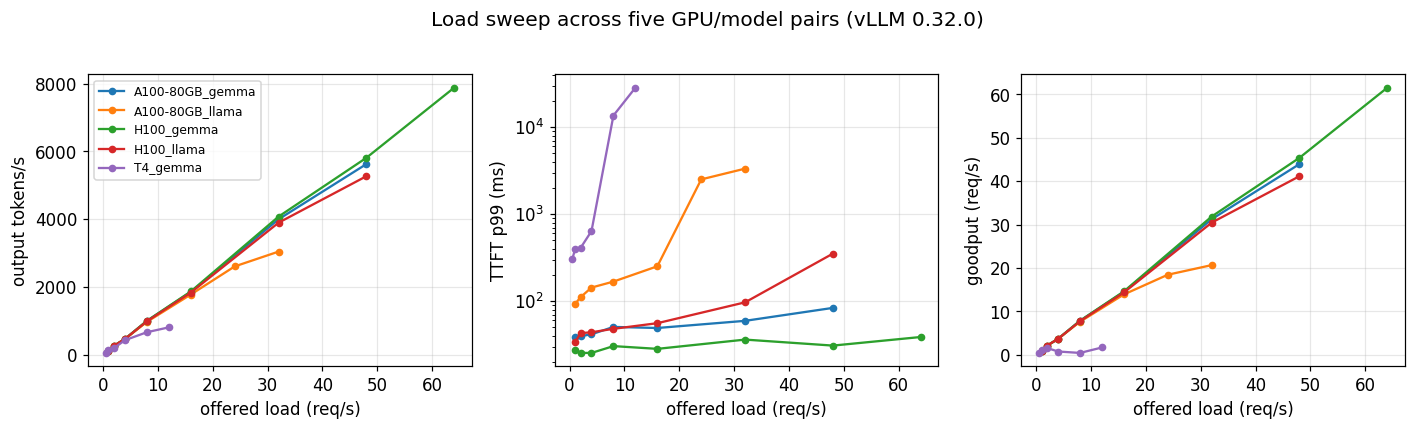

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for stem, d in data.items():
    runs = [r for r in d.get("sweep", {}).get("runs", []) if "ttft_ms" in r]
    if not runs:
        continue
    x = [r["rate"] for r in runs]
    ax[0].plot(x, [r["output_token_throughput"] for r in runs], marker="o", ms=4, label=stem)
    ax[1].plot(x, [r["ttft_ms"]["p99"] for r in runs], marker="o", ms=4, label=stem)
    ax[2].plot(x, [r["goodput_req_s"] for r in runs], marker="o", ms=4, label=stem)
for a, t in zip(ax, ("output tokens/s", "TTFT p99 (ms)", "goodput (req/s)")):
    a.set_xlabel("offered load (req/s)"); a.set_ylabel(t)
ax[1].set_yscale("log"); ax[0].legend(fontsize=8)
fig.suptitle("Load sweep across five GPU/model pairs (vLLM 0.32.0)", y=1.02)
fig.tight_layout(); plt.show()

The A100 and H100 hold 100% of their SLO across the whole sweep for Gemma; the T4
falls off a cliff above 4 req/s (it drops to the Triton attention backend and has
only about 7 GiB for KV). For Llama-3.1-8B the goodput knee comes earlier than for
Gemma on the same GPU, because the 8B model's larger KV footprint limits the batch.


### Long context: when the KV cache, not compute, caps the load

The long-context study sends 4,096-token prompts and 1,024-token answers, which keep
each request's KV resident far longer. Peak KV usage climbs toward 1.0 and the engine
starts preempting (evicting and recomputing) requests. That is the regime where
capacity, not FLOPs, is the limit.


In [11]:
for stem, d in data.items():
    runs = d.get("long", {}).get("runs", [])
    if not runs:
        continue
    print(f"\n{stem}  (long prompts, 4K in / 1K out)")
    print(f"  {'rate':>5}{'out tok/s':>11}{'TTFT p50/p99 (ms)':>20}{'TPOT p50':>10}{'peak KV':>9}{'preempt':>9}")
    for r in runs:
        if "ttft_ms" not in r:
            continue
        peak = r.get("metrics_peak", {})
        kv = max([v for k, v in peak.items() if "cache_usage" in k] or [0])
        pre = sum(v for k, v in r.get("metrics_after", {}).items() if "preemption" in k) \
            - sum(v for k, v in r.get("metrics_before", {}).items() if "preemption" in k)
        print(f"  {r['rate']:>5}{r['output_token_throughput']:>11.0f}"
              f"{r['ttft_ms']['p50']:>9.0f}/{r['ttft_ms']['p99']:<10.0f}"
              f"{r['tpot_ms']['p50']:>9.1f}{kv:>9.2f}{pre:>9.0f}")


A100-80GB_gemma  (long prompts, 4K in / 1K out)
   rate  out tok/s   TTFT p50/p99 (ms)  TPOT p50  peak KV  preempt
    0.5        411      127/174             4.6     0.01        0
    1.0       1012      129/230             5.0     0.02        0
    2.0       1709      136/244             5.8     0.02        0
    4.0       3450      239/634            13.9     0.12        0
    8.0       5125       93/13835           8.5     0.12        0

A100-80GB_llama  (long prompts, 4K in / 1K out)
   rate  out tok/s   TTFT p50/p99 (ms)  TPOT p50  peak KV  preempt
   0.25        203      329/545            12.8     0.06        0
    0.5        528      372/803            18.0     0.19        0
    1.0        676      405/1139           24.1     0.28        0
    2.0        979      953/22574          69.6     1.00        7
    3.0       1085     4525/68892          76.4     1.00       13
    4.0       1004    67821/148388         89.3     1.00       17

H100_gemma  (long prompts, 4K in / 1K out

### Prefix caching: the second turn of a conversation

With automatic prefix caching on, the second turn of a conversation reuses the KV of
the shared first turn instead of prefilling it again, so its time to first token
drops. This is the measured version of the block sharing shown in the paged-cache
cell above.


In [12]:
print(f"{'file':<22}{'prefix on TTFT p50/p99':>26}{'prefix off TTFT p50/p99':>27}")
print("-" * 75)
for stem, d in data.items():
    pf = d.get("prefix", {})
    on = pf.get("prefix_on", {}).get("follow_up", {})
    off = pf.get("prefix_off", {}).get("follow_up", {})
    if "ttft_ms" not in on or "ttft_ms" not in off:
        continue
    print(f"{stem:<22}{on['ttft_ms']['p50']:>15.0f}/{on['ttft_ms']['p99']:<10.0f}"
          f"{off['ttft_ms']['p50']:>16.0f}/{off['ttft_ms']['p99']:<10.0f}")

file                      prefix on TTFT p50/p99    prefix off TTFT p50/p99
---------------------------------------------------------------------------
A100-80GB_gemma                    21/28                      28/40        
A100-80GB_llama                    38/46                      72/535       
H100_gemma                         13/20                      15/24        
H100_llama                         22/28                      31/44        
T4_gemma                           94/125                    325/965       


### Speculative decoding, measured

n-gram (prompt-lookup) drafting proposes tokens by matching the recent context
against the prompt. It helps most at low load, where the target GPU is idle between
tokens; as the batch fills, the spare compute that verified the draft is no longer
free, so the benefit shrinks. The acceptance rate below is accepted draft tokens over
proposed draft tokens, read straight from vLLM's `spec_decode` counters.


In [13]:
def accepted_over_drafted(metrics):
    acc = sum(v for k, v in metrics.items() if "num_accepted_tokens_total" in k)
    dra = sum(v for k, v in metrics.items() if "num_draft_tokens_total" in k)
    return (acc / dra) if dra else None

for stem, d in data.items():
    spec = d.get("spec", {})
    if not spec:
        continue
    print(f"\n{stem}")
    for cfg in ("no_spec", "ngram"):
        sp = spec.get(cfg, {})
        if not isinstance(sp, dict) or "runs" not in sp:
            continue
        for rate, r in sp["runs"].items():
            if "tpot_ms" in r:
                print(f"  {cfg:<8} @ {rate:>5} req/s: TPOT p50 {r['tpot_ms']['p50']:>6.2f} ms, "
                      f"out tok/s {r['output_token_throughput']:>5.0f}")
        acc = accepted_over_drafted(sp.get("metrics", {}))
        if cfg == "ngram" and acc is not None:
            print(f"  ngram draft acceptance: {acc:.2f}  (accepted / proposed draft tokens)")


A100-80GB_gemma
  no_spec  @  0.25 req/s: TPOT p50   4.28 ms, out tok/s    25
  no_spec  @    32 req/s: TPOT p50   6.41 ms, out tok/s  3790
  ngram    @  0.25 req/s: TPOT p50   2.17 ms, out tok/s    25
  ngram    @    32 req/s: TPOT p50   4.15 ms, out tok/s  3816
  ngram draft acceptance: 0.49  (accepted / proposed draft tokens)

A100-80GB_llama
  no_spec  @  0.25 req/s: TPOT p50  10.85 ms, out tok/s    25
  no_spec  @    24 req/s: TPOT p50  47.31 ms, out tok/s  1990
  ngram    @  0.25 req/s: TPOT p50   7.53 ms, out tok/s    24
  ngram    @    24 req/s: TPOT p50  58.35 ms, out tok/s  1548
  ngram draft acceptance: 0.14  (accepted / proposed draft tokens)

H100_gemma
  no_spec  @  0.25 req/s: TPOT p50   2.37 ms, out tok/s    25
  no_spec  @    48 req/s: TPOT p50   3.35 ms, out tok/s  5694
  ngram    @  0.25 req/s: TPOT p50   1.33 ms, out tok/s    25
  ngram    @    48 req/s: TPOT p50   1.99 ms, out tok/s  5712
  ngram draft acceptance: 0.49  (accepted / proposed draft tokens)

H100_lla

Note the acceptance line is computed here directly from the `spec_decode` counters;
the shipped `summarize_results.py` filters those counters with a stricter key suffix
and prints no acceptance line, which is a display gap in that script, not missing
data. The counters themselves are in the result files, as this cell shows.


## Reproducing the measured cells

The analytical and KV-capacity cells above run anywhere. The measured cells read the
committed JSON. To regenerate that JSON you need GPUs and a Modal account with a
Hugging Face token (as a Modal secret named `huggingface`) that can read
`google/gemma-2b-it` and `meta-llama/Llama-3.1-8B-Instruct`:

```bash
modal run chapter08/modal_serving.py                    # all five pairs, all studies (a few hours)
modal run chapter08/modal_serving.py --gpus T4 --models gemma --studies single,sweep   # one quick pair
python chapter08/summarize_results.py                   # tables + results/sweep.png
```

To serve on your own GPU instead of Modal, build the workload once and point the load
generator at a running server:

```bash
python chapter08/build_prompts.py --out-dir data --num 1000
vllm serve google/gemma-2b-it --dtype float16 --max-model-len 2048
python chapter08/loadgen.py --model google/gemma-2b-it --prompts data/prompts_single.jsonl \
    --rate 4 --num 200 --max-tokens 128 --slo-ttft-ms 500 --slo-tpot-ms 50
```

The results committed here were served on an A100 80GB, an H100 and a T4 for Gemma,
and an A100 80GB and an H100 for Llama, all on vLLM 0.32.0. Serving engines change
their defaults between releases, so record the version with any new numbers.
